In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

CLEAN_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "online_retail_clean.parquet"
)

df = pd.read_parquet(CLEAN_DATA_PATH)

print("Dataset shape:", df.shape)
print("\nRelevant customer and transaction columns:")

relevant_columns = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "customer",
            "invoice",
            "purchase",
            "revenue",
            "quantity",
            "price",
            "transaction",
            "eligib",
            "date"
        ]
    )
]

display(
    pd.DataFrame({
        "column": relevant_columns,
        "dtype": [
            str(df[col].dtype)
            for col in relevant_columns
        ],
        "missing_values": [
            df[col].isna().sum()
            for col in relevant_columns
        ]
    })
)

Dataset shape: (1033036, 33)

Relevant customer and transaction columns:


,column,dtype,missing_values
0,Invoice,string,0
1,Quantity,int64,0
2,InvoiceDate,datetime64[us],0
3,Price,float64,0
4,Customer ID,float64,235151
5,has_customer_id,bool,0
6,has_positive_quantity,bool,0
7,has_positive_price,bool,0
8,candidate_paid_purchase,bool,0
9,is_zero_price,bool,0


In [2]:
# 1. Distribution of existing eligibility flags
eligibility_columns = [
    "has_customer_id",
    "candidate_paid_purchase",
    "customer_level_eligible",
    "qualifying_purchase",
    "is_customer_analytics_eligible",
    "is_qualifying_purchase"
]

for column in eligibility_columns:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))
    print(
        "Percentage:",
        (df[column].value_counts(normalize=True) * 100).round(2)
    )

# 2. Cross-tabulation of customer analytics eligibility
display(
    pd.crosstab(
        df["is_customer_analytics_eligible"],
        df["is_qualifying_purchase"],
        margins=True
    )
)

# 3. Transaction category breakdown
display(
    df.groupby(
        "transaction_category",
        dropna=False
    )
    .agg(
        record_count=("Invoice", "size"),
        identified_customers=("Customer ID", "nunique"),
        merchandise_revenue=("merchandise_revenue", "sum"),
        qualifying_purchase_revenue=(
            "qualifying_purchase_revenue", "sum"
        ),
        customer_analytics_eligible=(
            "is_customer_analytics_eligible", "sum"
        ),
        qualifying_purchase_records=(
            "is_qualifying_purchase", "sum"
        )
    )
    .sort_values("record_count", ascending=False)
    .reset_index()
)


has_customer_id
has_customer_id
True     797885
False    235151
Name: count, dtype: int64
Percentage: has_customer_id
True     77.24
False    22.76
Name: proportion, dtype: float64

candidate_paid_purchase
candidate_paid_purchase
True     779425
False    253611
Name: count, dtype: int64
Percentage: candidate_paid_purchase
True     75.45
False    24.55
Name: proportion, dtype: float64

customer_level_eligible
customer_level_eligible
True     796697
False    236339
Name: count, dtype: int64
Percentage: customer_level_eligible
True     77.12
False    22.88
Name: proportion, dtype: float64

qualifying_purchase
qualifying_purchase
True     776504
False    256532
Name: count, dtype: int64
Percentage: qualifying_purchase
True     75.17
False    24.83
Name: proportion, dtype: float64

is_customer_analytics_eligible
is_customer_analytics_eligible
True     794165
False    238871
Name: count, dtype: int64
Percentage: is_customer_analytics_eligible
True     76.88
False    23.12
Name: proportion, 

is_qualifying_purchase,False,True,All
is_customer_analytics_eligible,,,
False,238871,0,238871
True,17661,776504,794165
All,256532,776504,1033036


,transaction_category,record_count,identified_customers,merchandise_revenue,qualifying_purchase_revenue,customer_analytics_eligible,qualifying_purchase_records
0,merchandise_candidate,776504,5852,1.706728e+07,1.706728e+07,776504,776504
1,anonymous_merchandise_candidate,226838,0,2.577035e+06,0.000000e+00,0,0
2,merchandise_cancellation_candidate,17600,2446,-7.178935e+05,0.000000e+00,17600,0
3,delivery_charge,3869,599,0.000000e+00,0.000000e+00,0,0
4,operational_adjustment_candidate,3393,0,0.000000e+00,0.000000e+00,0,0
5,zero_price_activity,2593,43,0.000000e+00,0.000000e+00,61,0
6,manual_transaction,1392,582,0.000000e+00,0.000000e+00,0,0
7,anonymous_merchandise_cancellation_candidate,329,0,-6.542100e+03,0.000000e+00,0,0
8,discount_related_transaction,173,55,0.000000e+00,0.000000e+00,0,0
9,sample_transaction,101,0,0.000000e+00,0.000000e+00,0,0


In [3]:
# Separate qualifying purchases and customer-eligible cancellations
purchase_records = df[df["is_qualifying_purchase"]].copy()

cancellation_records = df[
    df["transaction_category"] == "merchandise_cancellation_candidate"
].copy()

# Identify customer populations
purchase_customers = set(
    purchase_records["Customer ID"].dropna().unique()
)

cancellation_customers = set(
    cancellation_records["Customer ID"].dropna().unique()
)

# Summary
population_summary = pd.DataFrame({
    "metric": [
        "Qualifying purchase records",
        "Customers with qualifying purchases",
        "Customer-eligible cancellation records",
        "Customers with cancellations",
        "Customers with both purchases and cancellations",
        "Customers with cancellations but no qualifying purchases"
    ],
    "value": [
        len(purchase_records),
        len(purchase_customers),
        len(cancellation_records),
        len(cancellation_customers),
        len(purchase_customers & cancellation_customers),
        len(cancellation_customers - purchase_customers)
    ]
})

display(population_summary)

# Verify qualifying purchases have customer identifiers
print(
    "\nQualifying purchase records missing Customer ID:",
    purchase_records["Customer ID"].isna().sum()
)

# Verify date coverage of qualifying purchases
print(
    "\nQualifying purchase date range:",
    purchase_records["InvoiceDate"].min(),
    "to",
    purchase_records["InvoiceDate"].max()
)

,metric,value
0,Qualifying purchase records,776504
1,Customers with qualifying purchases,5852
2,Customer-eligible cancellation records,17600
3,Customers with cancellations,2446
4,Customers with both purchases and cancellations,2423
5,Customers with cancellations but no qualifying...,23



Qualifying purchase records missing Customer ID: 0

Qualifying purchase date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


In [5]:
# Observation date
observation_date = pd.Timestamp("2011-12-10")

# Filter qualifying purchases
purchase_records = df[
    df["is_qualifying_purchase"]
].copy()

# Recreate analytical invoice group IDs
invoice_group_columns = [
    "Invoice",
    "InvoiceDate",
    "Customer ID",
    "Country"
]

purchase_records["invoice_group_id"] = (
    purchase_records
    .groupby(invoice_group_columns, dropna=False)
    .ngroup()
)

# Aggregate customer-level purchasing behavior
customer_df = (
    purchase_records
    .groupby("Customer ID")
    .agg(
        last_purchase_date=("InvoiceDate", "max"),
        frequency=("invoice_group_id", "nunique"),
        monetary=("qualifying_purchase_revenue", "sum"),
        purchase_lines=("Invoice", "size"),
        unique_products=("StockCode_normalized", "nunique")
    )
    .reset_index()
)

# Calculate recency
customer_df["recency"] = (
    observation_date - customer_df["last_purchase_date"].dt.normalize()
).dt.days

# Arrange columns
customer_df = customer_df[
    [
        "Customer ID",
        "last_purchase_date",
        "recency",
        "frequency",
        "monetary",
        "purchase_lines",
        "unique_products"
    ]
]

# Validate the customer-level dataset
print("Customer dataset shape:", customer_df.shape)
print("Unique customers:", customer_df["Customer ID"].nunique())
print("Missing values:", customer_df.isna().sum().sum())
print(
    "Duplicate customer IDs:",
    customer_df["Customer ID"].duplicated().sum()
)

display(customer_df.head(10))

Customer dataset shape: (5852, 7)
Unique customers: 5852
Missing values: 0
Duplicate customer IDs: 0


,Customer ID,last_purchase_date,recency,frequency,monetary,purchase_lines,unique_products
0,12346.0,2011-01-18 10:01:00,326,4,77353.96,26,26
1,12347.0,2011-12-07 15:52:00,3,8,4921.53,222,126
2,12348.0,2011-09-25 13:13:00,76,5,1658.40,46,24
3,12349.0,2011-11-21 09:51:00,19,3,3678.69,172,137
4,12350.0,2011-02-02 16:01:00,311,1,294.40,16,16
5,12351.0,2010-11-29 15:23:00,376,1,300.93,21,21
6,12352.0,2011-11-03 14:37:00,37,9,1729.54,95,68
7,12353.0,2011-05-19 17:47:00,205,2,406.76,24,23
8,12354.0,2011-04-21 13:11:00,233,1,1079.40,58,58
9,12355.0,2011-05-09 13:49:00,215,2,947.61,35,35


In [6]:
# Expected totals from qualifying purchase records
expected_purchase_records = len(purchase_records)

expected_monetary = (
    purchase_records["qualifying_purchase_revenue"].sum()
)

expected_invoice_groups = (
    purchase_records
    .groupby(
        [
            "Invoice",
            "InvoiceDate",
            "Customer ID",
            "Country"
        ],
        dropna=False
    )
    .ngroups
)

# Actual totals from customer-level dataset
actual_purchase_lines = customer_df["purchase_lines"].sum()
actual_monetary = customer_df["monetary"].sum()
actual_frequency = customer_df["frequency"].sum()

validation_results = pd.DataFrame({
    "metric": [
        "Qualifying purchase records",
        "Purchase invoice groups",
        "Qualifying purchase revenue"
    ],
    "expected": [
        expected_purchase_records,
        expected_invoice_groups,
        expected_monetary
    ],
    "actual": [
        actual_purchase_lines,
        actual_frequency,
        actual_monetary
    ]
})

validation_results["difference"] = (
    validation_results["actual"]
    - validation_results["expected"]
)

display(validation_results)

print(
    "\nAll validations passed:",
    np.allclose(
        validation_results["expected"],
        validation_results["actual"]
    )
)

,metric,expected,actual,difference
0,Qualifying purchase records,7.765040e+05,7.765040e+05,0.0
1,Purchase invoice groups,3.665900e+04,3.665900e+04,0.0
2,Qualifying purchase revenue,1.706728e+07,1.706728e+07,0.0



All validations passed: True


In [7]:
# RFM descriptive statistics
rfm_columns = ["recency", "frequency", "monetary"]

rfm_statistics = customer_df[rfm_columns].describe().T

rfm_statistics["skewness"] = (
    customer_df[rfm_columns].skew()
)

rfm_statistics["kurtosis"] = (
    customer_df[rfm_columns].kurtosis()
)

display(rfm_statistics)

# Distribution diagnostics
distribution_summary = pd.DataFrame({
    "metric": rfm_columns,
    "unique_values": [
        customer_df[col].nunique()
        for col in rfm_columns
    ],
    "zero_count": [
        (customer_df[col] == 0).sum()
        for col in rfm_columns
    ],
    "minimum": [
        customer_df[col].min()
        for col in rfm_columns
    ],
    "maximum": [
        customer_df[col].max()
        for col in rfm_columns
    ],
    "q25": [
        customer_df[col].quantile(0.25)
        for col in rfm_columns
    ],
    "median": [
        customer_df[col].median()
        for col in rfm_columns
    ],
    "q75": [
        customer_df[col].quantile(0.75)
        for col in rfm_columns
    ],
})

display(distribution_summary)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
recency,5852.0,200.732399,208.523287,1.00,26.00,96.00,380.00,739.00,0.894303,-0.457888
frequency,5852.0,6.264354,12.776372,1.00,1.00,3.00,7.00,375.00,12.075477,241.817389
monetary,5852.0,2916.486455,14306.825883,2.95,339.46,856.02,2241.03,580987.04,25.331353,849.499210


,metric,unique_values,zero_count,minimum,maximum,q25,median,q75
0,recency,592,0,1.00,739.00,26.00,96.00,380.00
1,frequency,84,0,1.00,375.00,1.00,3.00,7.00
2,monetary,5755,0,2.95,580987.04,339.46,856.02,2241.03


In [8]:
# Detailed percentile analysis
percentiles = [
    0.01, 0.05, 0.10,
    0.25, 0.50, 0.75,
    0.90, 0.95, 0.99, 0.995, 1.00
]

percentile_summary = (
    customer_df[["recency", "frequency", "monetary"]]
    .quantile(percentiles)
    .rename_axis("percentile")
    .reset_index()
)

percentile_summary["percentile"] = (
    percentile_summary["percentile"] * 100
)

display(
    percentile_summary.style.format({
        "percentile": "{:.1f}%",
        "recency": "{:,.0f}",
        "frequency": "{:,.0f}",
        "monetary": "{:,.2f}"
    })
)

# Customers at the extreme upper end of frequency and monetary value
print("\nTop 10 customers by frequency:")

display(
    customer_df.nlargest(10, "frequency")[
        ["Customer ID", "recency", "frequency", "monetary"]
    ]
)

print("\nTop 10 customers by monetary value:")

display(
    customer_df.nlargest(10, "monetary")[
        ["Customer ID", "recency", "frequency", "monetary"]
    ]
)

,percentile,recency,frequency,monetary
0,1.0%,2,1,45.32
1,5.0%,4,1,112.50
2,10.0%,9,1,161.35
3,25.0%,26,1,339.46
4,50.0%,96,3,856.02
5,75.0%,380,7,"2,241.03"
6,90.0%,531,13,"5,392.77"
7,95.0%,624,20,"9,270.27"
8,99.0%,727,46,"28,631.08"
9,99.5%,734,68,"53,918.37"



Top 10 customers by frequency:


,Customer ID,recency,frequency,monetary
2520,14911.0,2,375,272245.29
393,12748.0,1,323,49176.74
5408,17841.0,2,211,68519.95
2916,15311.0,1,207,114671.42
730,13089.0,3,203,113416.91
2222,14606.0,2,186,29648.75
5416,17850.0,373,155,51208.87
2262,14646.0,2,145,526751.52
5666,18102.0,1,145,580987.04
1778,14156.0,10,144,303069.88



Top 10 customers by monetary value:


,Customer ID,recency,frequency,monetary
5666,18102.0,1,145,580987.04
2262,14646.0,2,145,526751.52
1778,14156.0,10,144,303069.88
2520,14911.0,2,375,272245.29
5026,17450.0,9,51,244784.25
1321,13694.0,4,143,195640.69
5085,17511.0,3,61,172132.87
4037,16446.0,1,2,168472.50
4271,16684.0,5,55,147142.77
67,12415.0,25,24,144033.37


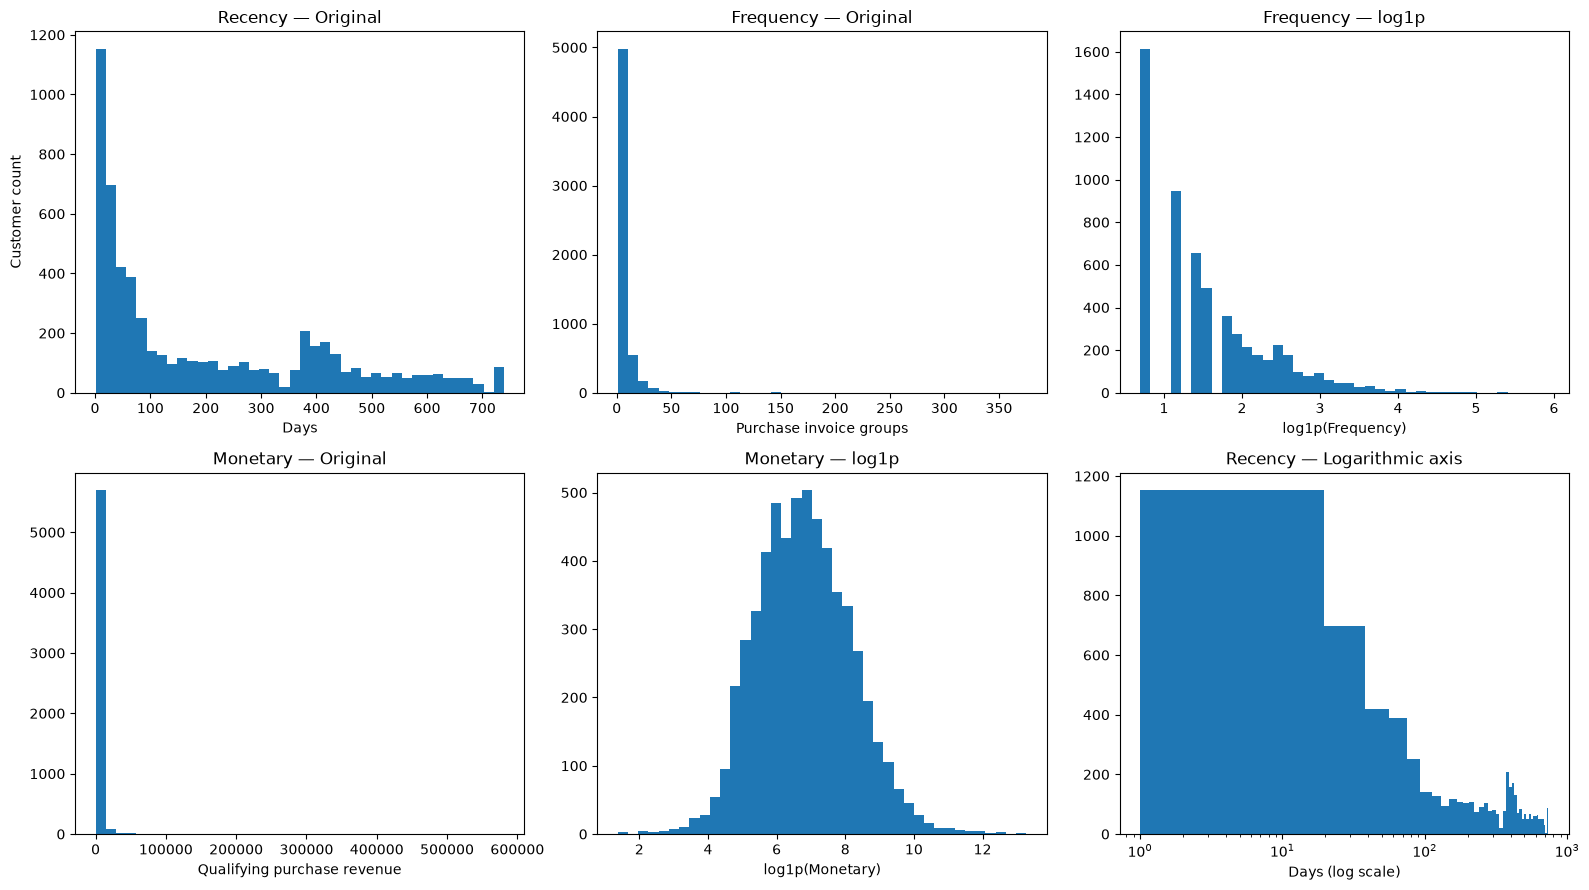

In [9]:
import matplotlib.pyplot as plt

# Prepare transformed values for visual inspection
customer_df["frequency_log1p"] = np.log1p(customer_df["frequency"])
customer_df["monetary_log1p"] = np.log1p(customer_df["monetary"])

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Recency: raw distribution
axes[0, 0].hist(customer_df["recency"], bins=40)
axes[0, 0].set_title("Recency — Original")
axes[0, 0].set_xlabel("Days")
axes[0, 0].set_ylabel("Customer count")

# Frequency: original and transformed
axes[0, 1].hist(customer_df["frequency"], bins=40)
axes[0, 1].set_title("Frequency — Original")
axes[0, 1].set_xlabel("Purchase invoice groups")

axes[0, 2].hist(customer_df["frequency_log1p"], bins=40)
axes[0, 2].set_title("Frequency — log1p")
axes[0, 2].set_xlabel("log1p(Frequency)")

# Monetary: original and transformed
axes[1, 0].hist(customer_df["monetary"], bins=40)
axes[1, 0].set_title("Monetary — Original")
axes[1, 0].set_xlabel("Qualifying purchase revenue")

axes[1, 1].hist(customer_df["monetary_log1p"], bins=40)
axes[1, 1].set_title("Monetary — log1p")
axes[1, 1].set_xlabel("log1p(Monetary)")

# Recency with logarithmic x-axis for comparison
axes[1, 2].hist(customer_df["recency"], bins=40)
axes[1, 2].set_xscale("log")
axes[1, 2].set_title("Recency — Logarithmic axis")
axes[1, 2].set_xlabel("Days (log scale)")

plt.tight_layout()
plt.show()

In [10]:
# Recency distribution by 30-day intervals
recency_bins = list(range(0, 781, 30))

customer_df["recency_band"] = pd.cut(
    customer_df["recency"],
    bins=recency_bins,
    right=False
)

recency_band_summary = (
    customer_df
    .groupby("recency_band", observed=False)
    .agg(
        customer_count=("Customer ID", "count"),
        percentage=("Customer ID", lambda x: len(x) / len(customer_df) * 100)
    )
    .reset_index()
)

display(
    recency_band_summary.style.format({
        "customer_count": "{:,.0f}",
        "percentage": "{:.2f}%"
    })
)

# Inspect the customers around the apparent concentration
print("Customers with recency between 350 and 420 days:")

display(
    customer_df.loc[
        customer_df["recency"].between(350, 420),
        ["Customer ID", "last_purchase_date", "recency", "frequency", "monetary"]
    ]
    .sort_values("recency")
    .head(20)
)

,recency_band,customer_count,percentage
0,"[0, 30)","1,571",26.85%
1,"[30, 60)",779,13.31%
2,"[60, 90)",521,8.90%
3,"[90, 120)",231,3.95%
4,"[120, 150)",178,3.04%
5,"[150, 180)",183,3.13%
6,"[180, 210)",164,2.80%
7,"[210, 240)",141,2.41%
8,"[240, 270)",171,2.92%
9,"[270, 300)",123,2.10%


Customers with recency between 350 and 420 days:


,Customer ID,last_purchase_date,recency,frequency,monetary
941,13304.0,2010-12-23 14:35:00,352,4,1217.99
1546,13922.0,2010-12-23 10:38:00,352,3,865.20
3164,15562.0,2010-12-23 09:55:00,352,3,671.43
380,12734.0,2010-12-22 12:47:00,353,3,603.65
3862,16270.0,2010-12-21 14:26:00,354,1,1141.24
166,12515.0,2010-12-21 15:43:00,354,1,278.70
3062,15460.0,2010-12-20 16:08:00,355,1,214.26
1193,13564.0,2010-12-20 16:50:00,355,36,15880.22
2884,15279.0,2010-12-20 10:48:00,355,5,1580.54
4922,17343.0,2010-12-19 15:07:00,356,6,1259.94


,last_purchase_month,customer_count,median_recency,total_monetary,percentage
0,2009-12,89,731.0,"26,964.37",1.52%
1,2010-01,49,687.0,"30,489.82",0.84%
2,2010-02,73,664.0,"34,348.21",1.25%
3,2010-03,103,632.0,"77,125.52",1.76%
4,2010-04,91,599.0,"60,771.28",1.56%
5,2010-05,92,576.0,"80,761.64",1.57%
6,2010-06,105,543.0,"69,031.22",1.79%
7,2010-07,93,510.0,"67,646.45",1.59%
8,2010-08,106,479.0,"67,508.07",1.81%
9,2010-09,138,450.0,"105,086.54",2.36%


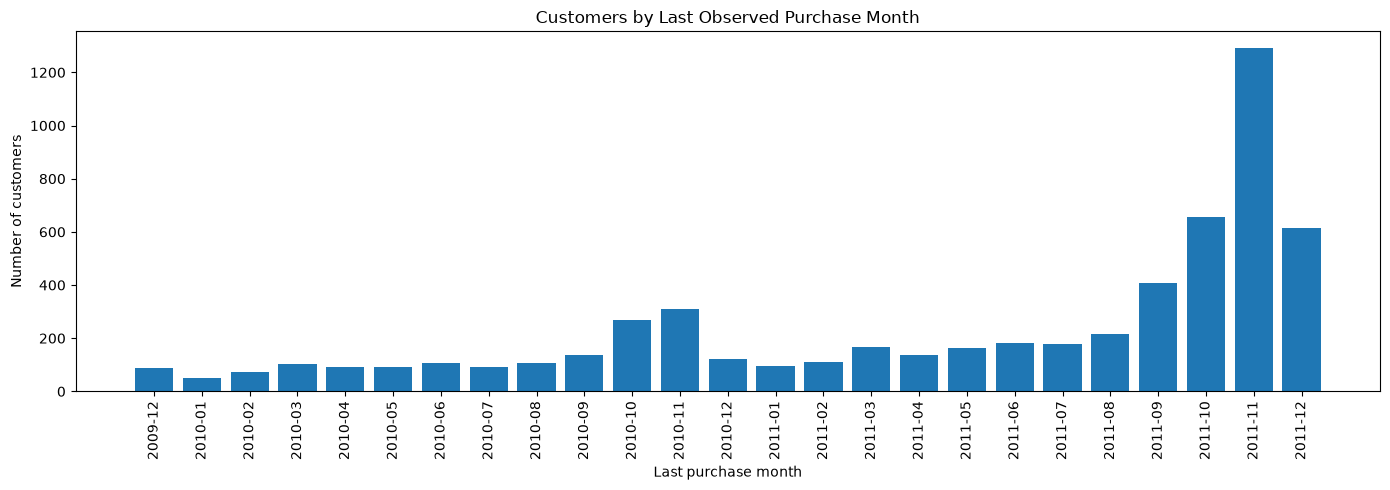

In [11]:
# Distribution of customers by their last observed purchase month
customer_df["last_purchase_month"] = (
    customer_df["last_purchase_date"].dt.to_period("M")
)

last_purchase_month_summary = (
    customer_df
    .groupby("last_purchase_month")
    .agg(
        customer_count=("Customer ID", "nunique"),
        median_recency=("recency", "median"),
        total_monetary=("monetary", "sum")
    )
    .reset_index()
)

last_purchase_month_summary["percentage"] = (
    last_purchase_month_summary["customer_count"]
    / len(customer_df) * 100
)

display(
    last_purchase_month_summary.style.format({
        "customer_count": "{:,.0f}",
        "median_recency": "{:.1f}",
        "total_monetary": "{:,.2f}",
        "percentage": "{:.2f}%"
    })
)

# Visualize the distribution
plt.figure(figsize=(14, 5))
plt.bar(
    last_purchase_month_summary["last_purchase_month"].astype(str),
    last_purchase_month_summary["customer_count"]
)
plt.title("Customers by Last Observed Purchase Month")
plt.xlabel("Last purchase month")
plt.ylabel("Number of customers")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [12]:
# Customer revenue concentration by decile

customer_value = customer_df[
    ["Customer ID", "monetary"]
].copy()

# Rank first to ensure exactly ten groups despite tied monetary values
customer_value["revenue_decile"] = pd.qcut(
    customer_value["monetary"].rank(method="first"),
    q=10,
    labels=False
) + 1

decile_summary = (
    customer_value
    .groupby("revenue_decile", observed=True)
    .agg(
        customer_count=("Customer ID", "nunique"),
        total_revenue=("monetary", "sum"),
        median_customer_revenue=("monetary", "median"),
        average_customer_revenue=("monetary", "mean")
    )
    .reset_index()
)

total_revenue = customer_value["monetary"].sum()

decile_summary["revenue_share"] = (
    decile_summary["total_revenue"] / total_revenue * 100
)

decile_summary["cumulative_revenue_share"] = (
    decile_summary["revenue_share"].cumsum()
)

display(
    decile_summary.style.format({
        "customer_count": "{:,.0f}",
        "total_revenue": "{:,.2f}",
        "median_customer_revenue": "{:,.2f}",
        "average_customer_revenue": "{:,.2f}",
        "revenue_share": "{:.2f}%",
        "cumulative_revenue_share": "{:.2f}%"
    })
)

,revenue_decile,customer_count,total_revenue,median_customer_revenue,average_customer_revenue,revenue_share,cumulative_revenue_share
0,1,586,"62,342.08",112.50,106.39,0.37%,0.37%
1,2,585,"127,581.75",216.17,218.09,0.75%,1.11%
2,3,585,"200,090.85",339.50,342.04,1.17%,2.29%
3,4,585,"290,437.86",496.06,496.47,1.70%,3.99%
4,5,585,"423,530.13",723.85,723.98,2.48%,6.47%
5,6,585,"598,570.91","1,019.27","1,023.20",3.51%,9.98%
6,7,585,"864,059.67","1,455.39","1,477.03",5.06%,15.04%
7,8,585,"1,329,627.50","2,240.90","2,272.87",7.79%,22.83%
8,9,585,"2,265,866.15","3,767.09","3,873.28",13.28%,36.10%
9,10,586,"10,905,171.83","9,270.74","18,609.51",63.90%,100.00%


In [13]:
# Revenue concentration among the highest-value customers

customer_value_sorted = customer_value.sort_values(
    "monetary",
    ascending=False
).reset_index(drop=True)

total_customer_revenue = customer_value_sorted["monetary"].sum()

concentration_rows = []

for percentage in [1, 5, 10, 20, 30, 50]:
    customer_count = int(np.ceil(len(customer_value_sorted) * percentage / 100))

    selected_customers = customer_value_sorted.head(customer_count)

    revenue = selected_customers["monetary"].sum()

    concentration_rows.append({
        "top_customer_percentage": percentage,
        "customer_count": customer_count,
        "total_revenue": revenue,
        "revenue_share": revenue / total_customer_revenue * 100
    })

concentration_summary = pd.DataFrame(concentration_rows)

display(
    concentration_summary.style.format({
        "top_customer_percentage": "{:.0f}%",
        "customer_count": "{:,.0f}",
        "total_revenue": "{:,.2f}",
        "revenue_share": "{:.2f}%"
    })
)

,top_customer_percentage,customer_count,total_revenue,revenue_share
0,1%,59,"5,476,706.34",32.09%
1,5%,293,"8,872,142.49",51.98%
2,10%,586,"10,905,171.83",63.90%
3,20%,"1,171","13,171,037.98",77.17%
4,30%,"1,756","14,500,665.48",84.96%
5,50%,"2,926","15,963,296.06",93.53%


In [14]:
# Inspect five-level quantile boundaries for RFM metrics

quantile_levels = [0, 0.2, 0.4, 0.6, 0.8, 1.0]

rfm_quantile_boundaries = {}

for metric in ["recency", "frequency", "monetary"]:
    boundaries = customer_df[metric].quantile(quantile_levels)

    rfm_quantile_boundaries[metric] = boundaries

    print(f"\n{metric.upper()} quantile boundaries:")
    display(boundaries.to_frame(name="boundary"))

    print(
        "Number of unique boundaries:",
        boundaries.nunique()
    )

    print(
        "Number of duplicated boundaries:",
        boundaries.duplicated().sum()
    )


RECENCY quantile boundaries:


,boundary
0.0,1.0
0.2,20.0
0.4,59.0
0.6,187.0
0.8,409.0
1.0,739.0


Number of unique boundaries: 6
Number of duplicated boundaries: 0

FREQUENCY quantile boundaries:


,boundary
0.0,1.0
0.2,1.0
0.4,2.0
0.6,4.0
0.8,8.0
1.0,375.0


Number of unique boundaries: 5
Number of duplicated boundaries: 1

MONETARY quantile boundaries:


,boundary
0.0,2.950
0.2,285.352
0.4,603.318
0.6,1204.952
0.8,2887.414
1.0,580987.040


Number of unique boundaries: 6
Number of duplicated boundaries: 0


In [15]:
# Inspect proposed frequency scoring groups

frequency_bins = [0, 1, 2, 4, 8, float("inf")]
frequency_labels = [
    "1 invoice",
    "2 invoices",
    "3-4 invoices",
    "5-8 invoices",
    "9+ invoices"
]

customer_df["frequency_group"] = pd.cut(
    customer_df["frequency"],
    bins=frequency_bins,
    labels=frequency_labels
)

frequency_group_summary = (
    customer_df
    .groupby("frequency_group", observed=False)
    .agg(
        customer_count=("Customer ID", "nunique"),
        median_frequency=("frequency", "median"),
        total_monetary=("monetary", "sum"),
        median_monetary=("monetary", "median")
    )
    .reset_index()
)

frequency_group_summary["customer_percentage"] = (
    frequency_group_summary["customer_count"]
    / len(customer_df) * 100
)

frequency_group_summary["revenue_share"] = (
    frequency_group_summary["total_monetary"]
    / customer_df["monetary"].sum() * 100
)

display(
    frequency_group_summary.style.format({
        "customer_count": "{:,.0f}",
        "median_frequency": "{:.1f}",
        "total_monetary": "{:,.2f}",
        "median_monetary": "{:,.2f}",
        "customer_percentage": "{:.2f}%",
        "revenue_share": "{:.2f}%"
    })
)

,frequency_group,customer_count,median_frequency,total_monetary,median_monetary,customer_percentage,revenue_share
0,1 invoice,"1,615",1.0,"555,043.74",228.91,27.60%,3.25%
1,2 invoices,945,2.0,"806,138.26",512.20,16.15%,4.72%
2,3-4 invoices,"1,146",3.0,"1,451,431.59",906.69,19.58%,8.50%
3,5-8 invoices,"1,027",6.0,"2,334,775.99","1,770.96",17.55%,13.68%
4,9+ invoices,"1,119",14.0,"11,919,889.15","4,905.53",19.12%,69.84%


In [16]:
# Create rule-based RFM scores

rfm_df = customer_df[
    [
        "Customer ID",
        "last_purchase_date",
        "recency",
        "frequency",
        "monetary"
    ]
].copy()

# Recency: lower values receive higher scores
rfm_df["R_score"] = pd.qcut(
    rfm_df["recency"].rank(method="first"),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: business-defined thresholds
rfm_df["F_score"] = pd.cut(
    rfm_df["frequency"],
    bins=[0, 1, 2, 4, 8, float("inf")],
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: higher values receive higher scores
rfm_df["M_score"] = pd.qcut(
    rfm_df["monetary"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combined RFM score
rfm_df["RFM_score"] = (
    rfm_df["R_score"].astype(str)
    + rfm_df["F_score"].astype(str)
    + rfm_df["M_score"].astype(str)
)

# Simple additive score for initial comparison
rfm_df["RFM_total"] = (
    rfm_df["R_score"]
    + rfm_df["F_score"]
    + rfm_df["M_score"]
)

display(rfm_df.head(10))

print("\nScore distributions:")

for score in ["R_score", "F_score", "M_score", "RFM_total"]:
    print(f"\n{score}")
    display(
        rfm_df[score]
        .value_counts()
        .sort_index()
        .rename("customer_count")
        .to_frame()
    )

,Customer ID,last_purchase_date,recency,frequency,monetary,R_score,F_score,M_score,RFM_score,RFM_total
0,12346.0,2011-01-18 10:01:00,326,4,77353.96,2,3,5,235,10
1,12347.0,2011-12-07 15:52:00,3,8,4921.53,5,4,5,545,14
2,12348.0,2011-09-25 13:13:00,76,5,1658.40,3,4,4,344,11
3,12349.0,2011-11-21 09:51:00,19,3,3678.69,5,3,5,535,13
4,12350.0,2011-02-02 16:01:00,311,1,294.40,2,1,2,212,5
5,12351.0,2010-11-29 15:23:00,376,1,300.93,2,1,2,212,5
6,12352.0,2011-11-03 14:37:00,37,9,1729.54,4,5,4,454,13
7,12353.0,2011-05-19 17:47:00,205,2,406.76,2,2,2,222,6
8,12354.0,2011-04-21 13:11:00,233,1,1079.40,2,1,3,213,6
9,12355.0,2011-05-09 13:49:00,215,2,947.61,2,2,3,223,7



Score distributions:

R_score


,customer_count
R_score,
1,1171
2,1170
3,1170
4,1170
5,1171



F_score


,customer_count
F_score,
1,1615
2,945
3,1146
4,1027
5,1119



M_score


,customer_count
M_score,
1,1171
2,1170
3,1170
4,1170
5,1171



RFM_total


,customer_count
RFM_total,
3,442
4,526
5,434
6,471
7,457
8,481
9,470
10,449
11,457


In [17]:
# Profile customers by combined RFM total score

rfm_score_profile = (
    rfm_df
    .groupby("RFM_total")
    .agg(
        customer_count=("Customer ID", "nunique"),
        median_recency=("recency", "median"),
        median_frequency=("frequency", "median"),
        median_monetary=("monetary", "median"),
        total_monetary=("monetary", "sum"),
        average_R_score=("R_score", "mean"),
        average_F_score=("F_score", "mean"),
        average_M_score=("M_score", "mean")
    )
    .reset_index()
)

rfm_score_profile["customer_percentage"] = (
    rfm_score_profile["customer_count"]
    / len(rfm_df) * 100
)

rfm_score_profile["revenue_share"] = (
    rfm_score_profile["total_monetary"]
    / rfm_df["monetary"].sum() * 100
)

display(
    rfm_score_profile.style.format({
        "customer_count": "{:,.0f}",
        "median_recency": "{:.1f}",
        "median_frequency": "{:.1f}",
        "median_monetary": "{:,.2f}",
        "total_monetary": "{:,.2f}",
        "average_R_score": "{:.2f}",
        "average_F_score": "{:.2f}",
        "average_M_score": "{:.2f}",
        "customer_percentage": "{:.2f}%",
        "revenue_share": "{:.2f}%"
    })
)

,RFM_total,customer_count,median_recency,median_frequency,median_monetary,total_monetary,average_R_score,average_F_score,average_M_score,customer_percentage,revenue_share
0,3,442,570.0,1.0,148.99,"66,425.01",1.00,1.00,1.00,7.55%,0.39%
1,4,526,414.5,1.0,242.20,"133,310.68",1.47,1.11,1.41,8.99%,0.78%
2,5,434,333.0,1.0,315.93,"152,402.70",1.98,1.34,1.68,7.42%,0.89%
3,6,471,236.0,2.0,393.64,"220,216.27",2.40,1.62,1.98,8.05%,1.29%
4,7,457,205.0,2.0,546.81,"311,689.19",2.60,2.06,2.35,7.81%,1.83%
5,8,481,149.0,3.0,700.41,"398,375.67",2.85,2.47,2.68,8.22%,2.33%
6,9,470,93.0,3.0,916.44,"515,974.12",3.07,2.89,3.04,8.03%,3.02%
7,10,449,69.0,4.0,"1,094.84","751,200.82",3.34,3.26,3.41,7.67%,4.40%
8,11,457,61.0,5.0,"1,563.61","921,730.28",3.57,3.64,3.79,7.81%,5.40%
9,12,409,37.0,6.0,"1,969.60","1,378,966.92",3.88,4.04,4.08,6.99%,8.08%


In [18]:
# Analyze distinct RFM score combinations

rfm_combination_profile = (
    rfm_df
    .groupby(
        ["R_score", "F_score", "M_score"],
        observed=True
    )
    .agg(
        customer_count=("Customer ID", "nunique"),
        median_recency=("recency", "median"),
        median_frequency=("frequency", "median"),
        median_monetary=("monetary", "median"),
        total_monetary=("monetary", "sum")
    )
    .reset_index()
)

total_customers = rfm_df["Customer ID"].nunique()
total_revenue = rfm_df["monetary"].sum()

rfm_combination_profile["customer_percentage"] = (
    rfm_combination_profile["customer_count"]
    / total_customers * 100
)

rfm_combination_profile["revenue_share"] = (
    rfm_combination_profile["total_monetary"]
    / total_revenue * 100
)

rfm_combination_profile["RFM_total"] = (
    rfm_combination_profile["R_score"]
    + rfm_combination_profile["F_score"]
    + rfm_combination_profile["M_score"]
)

rfm_combination_profile = rfm_combination_profile.sort_values(
    ["R_score", "F_score", "M_score"],
    ascending=[False, False, False]
)

display(
    rfm_combination_profile.style.format({
        "customer_count": "{:,.0f}",
        "median_recency": "{:.1f}",
        "median_frequency": "{:.1f}",
        "median_monetary": "{:,.2f}",
        "total_monetary": "{:,.2f}",
        "customer_percentage": "{:.2f}%",
        "revenue_share": "{:.2f}%"
    })
)

print(
    "Number of observed RFM combinations:",
    len(rfm_combination_profile)
)

,R_score,F_score,M_score,customer_count,median_recency,median_frequency,median_monetary,total_monetary,customer_percentage,revenue_share,RFM_total
112,5,5,5,461,8.0,20.0,"7,571.35","7,991,324.72",7.88%,46.82%,15
111,5,5,4,87,9.0,10.0,"2,317.43","194,792.95",1.49%,1.14%,14
110,5,5,3,4,5.0,10.0,972.31,"3,931.88",0.07%,0.02%,13
109,5,5,2,1,12.0,13.0,485.69,485.69,0.02%,0.00%,12
108,5,4,5,52,10.0,7.0,"3,889.81","255,762.67",0.89%,1.50%,14
107,5,4,4,127,9.0,6.0,"1,793.22","243,648.98",2.17%,1.43%,13
106,5,4,3,67,12.0,6.0,977.93,"63,710.79",1.14%,0.37%,12
105,5,4,2,6,8.0,5.5,526.64,"3,094.24",0.10%,0.02%,11
104,5,3,5,9,10.0,4.0,"3,678.69","46,802.60",0.15%,0.27%,13
103,5,3,4,50,9.5,4.0,"1,448.30","81,841.25",0.85%,0.48%,12


Number of observed RFM combinations: 113


In [19]:
# Assign preliminary business-facing RFM segments

conditions = [
    (
        (rfm_df["R_score"] >= 4)
        & (rfm_df["F_score"] >= 4)
        & (rfm_df["M_score"] >= 4)
    ),
    (
        (rfm_df["R_score"] >= 3)
        & (rfm_df["F_score"] >= 4)
    ),
    (
        (rfm_df["R_score"] >= 4)
        & (rfm_df["M_score"] >= 4)
    ),
    (
        (rfm_df["R_score"] <= 2)
        & (
            (rfm_df["F_score"] >= 3)
            | (rfm_df["M_score"] >= 4)
        )
    ),
    (
        (rfm_df["R_score"] <= 2)
        & (rfm_df["F_score"] <= 2)
        & (rfm_df["M_score"] <= 2)
    )
]

segment_labels = [
    "Champions",
    "Loyal customers",
    "Recent high-value",
    "At-risk valuable",
    "Hibernating"
]

rfm_df["rfm_segment"] = np.select(
    conditions,
    segment_labels,
    default="Other customers"
)

# Profile each segment
rfm_segment_profile = (
    rfm_df
    .groupby("rfm_segment")
    .agg(
        customer_count=("Customer ID", "nunique"),
        median_recency=("recency", "median"),
        median_frequency=("frequency", "median"),
        median_monetary=("monetary", "median"),
        total_monetary=("monetary", "sum")
    )
    .reset_index()
)

total_revenue = rfm_df["monetary"].sum()

rfm_segment_profile["customer_percentage"] = (
    rfm_segment_profile["customer_count"]
    / len(rfm_df) * 100
)

rfm_segment_profile["revenue_share"] = (
    rfm_segment_profile["total_monetary"]
    / total_revenue * 100
)

display(
    rfm_segment_profile.style.format({
        "customer_count": "{:,.0f}",
        "median_recency": "{:.1f}",
        "median_frequency": "{:.1f}",
        "median_monetary": "{:,.2f}",
        "total_monetary": "{:,.2f}",
        "customer_percentage": "{:.2f}%",
        "revenue_share": "{:.2f}%"
    })
)

print(
    "\nTotal customers assigned:",
    rfm_segment_profile["customer_count"].sum()
)

print(
    "Unique customers in RFM dataset:",
    rfm_df["Customer ID"].nunique()
)

,rfm_segment,customer_count,median_recency,median_frequency,median_monetary,total_monetary,customer_percentage,revenue_share
0,At-risk valuable,782,372.5,4.0,"1,216.32","1,698,154.20",13.36%,9.95%
1,Champions,"1,254",17.0,11.0,"3,968.39","11,555,689.88",21.43%,67.71%
2,Hibernating,"1,352",435.0,1.0,235.82,"347,790.42",23.10%,2.04%
3,Loyal customers,603,79.0,7.0,"1,906.07","1,742,374.26",10.30%,10.21%
4,Other customers,"1,693",65.0,2.0,606.02,"1,193,565.52",28.93%,6.99%
5,Recent high-value,168,23.5,3.0,"1,540.64","529,704.44",2.87%,3.10%



Total customers assigned: 5852
Unique customers in RFM dataset: 5852


In [20]:
from sklearn.preprocessing import StandardScaler

# Prepare clustering features
clustering_features = pd.DataFrame({
    "recency": rfm_df["recency"],
    "frequency_log1p": np.log1p(rfm_df["frequency"]),
    "monetary_log1p": np.log1p(rfm_df["monetary"])
}, index=rfm_df.index)

# Standardize features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(clustering_features)

# Keep feature names and customer index
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=clustering_features.columns,
    index=rfm_df.index
)

# Validate preprocessing
print("Clustering dataset shape:", X_scaled_df.shape)

print("\nMissing values:")
display(X_scaled_df.isna().sum().to_frame("missing_count"))

print("\nStandardized feature statistics:")
display(X_scaled_df.describe().T)

print("\nFeature means:")
print(X_scaled_df.mean())

print("\nFeature standard deviations:")
print(X_scaled_df.std())

Clustering dataset shape: (5852, 3)

Missing values:


,missing_count
recency,0
frequency_log1p,0
monetary_log1p,0



Standardized feature statistics:


,count,mean,std,min,25%,50%,75%,max
recency,5852.0,-6.799452e-17,1.000085,-0.957924,-0.838023,-0.502300,0.859774,2.581551
frequency_log1p,5852.0,1.997339e-16,1.000085,-1.058337,-1.058337,-0.200597,0.657144,5.421541
monetary_log1p,5852.0,-1.457025e-17,1.000085,-3.935822,-0.708179,-0.039585,0.656900,4.681765



Feature means:
recency           -6.799452e-17
frequency_log1p    1.997339e-16
monetary_log1p    -1.457025e-17
dtype: float64

Feature standard deviations:
recency            1.000085
frequency_log1p    1.000085
monetary_log1p     1.000085
dtype: float64


In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Evaluate candidate cluster counts
cluster_range = range(2, 11)

cluster_evaluation = []

for k in cluster_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled_df)

    inertia = kmeans.inertia_

    silhouette = silhouette_score(
        X_scaled_df,
        cluster_labels
    )

    cluster_evaluation.append({
        "n_clusters": k,
        "inertia": inertia,
        "silhouette_score": silhouette
    })

cluster_evaluation_df = pd.DataFrame(cluster_evaluation)

display(
    cluster_evaluation_df.style.format({
        "inertia": "{:,.2f}",
        "silhouette_score": "{:.4f}"
    })
)

,n_clusters,inertia,silhouette_score
0,2,"8,854.55",0.4183
1,3,"5,698.14",0.4015
2,4,"4,458.06",0.3614
3,5,"3,631.42",0.3645
4,6,"3,071.22",0.3481
5,7,"2,729.98",0.3357
6,8,"2,466.09",0.3156
7,9,"2,282.52",0.3106
8,10,"2,131.14",0.2997


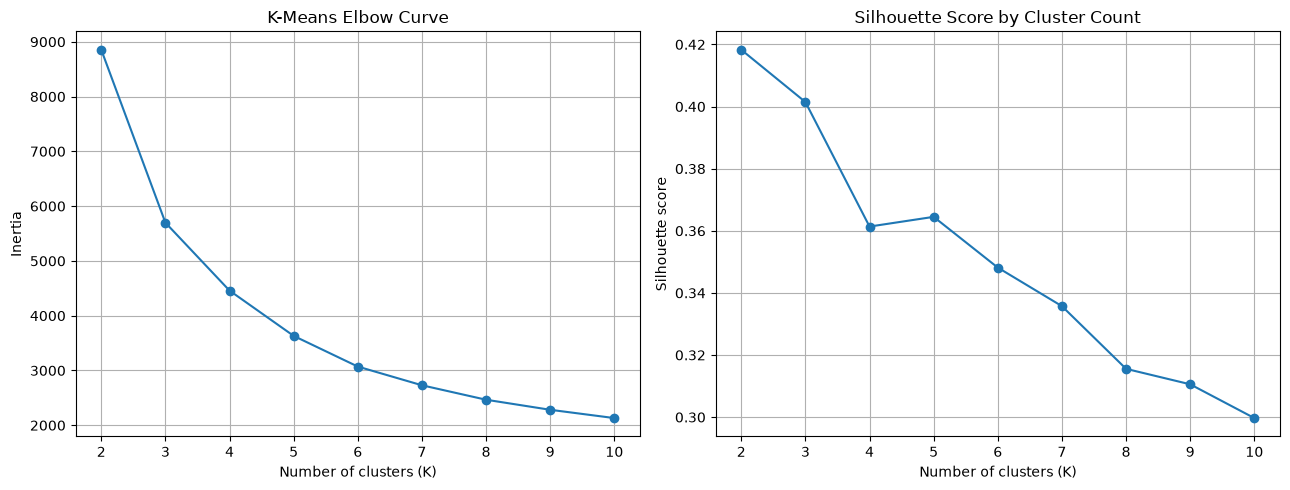

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Inertia / elbow curve
axes[0].plot(
    cluster_evaluation_df["n_clusters"],
    cluster_evaluation_df["inertia"],
    marker="o"
)
axes[0].set_title("K-Means Elbow Curve")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(cluster_range)
axes[0].grid(True)

# Silhouette scores
axes[1].plot(
    cluster_evaluation_df["n_clusters"],
    cluster_evaluation_df["silhouette_score"],
    marker="o"
)
axes[1].set_title("Silhouette Score by Cluster Count")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_xticks(cluster_range)
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [23]:
# Compare candidate K-Means solutions
candidate_ks = [2, 3, 4]

candidate_models = {}
candidate_labels = {}

for k in candidate_ks:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled_df)

    candidate_models[k] = model
    candidate_labels[k] = labels

# Generate cluster profiles for each candidate
for k in candidate_ks:
    print(f"\n{'=' * 50}")
    print(f"K = {k}")
    print(f"{'=' * 50}")

    profile_data = rfm_df[
        ["Customer ID", "recency", "frequency", "monetary"]
    ].copy()

    profile_data["cluster"] = candidate_labels[k]

    cluster_profile = (
        profile_data
        .groupby("cluster")
        .agg(
            customer_count=("Customer ID", "nunique"),
            median_recency=("recency", "median"),
            median_frequency=("frequency", "median"),
            median_monetary=("monetary", "median"),
            total_monetary=("monetary", "sum")
        )
        .reset_index()
    )

    cluster_profile["customer_percentage"] = (
        cluster_profile["customer_count"]
        / len(profile_data) * 100
    )

    cluster_profile["revenue_share"] = (
        cluster_profile["total_monetary"]
        / profile_data["monetary"].sum() * 100
    )

    display(
        cluster_profile.style.format({
            "customer_count": "{:,.0f}",
            "median_recency": "{:.1f}",
            "median_frequency": "{:.1f}",
            "median_monetary": "{:,.2f}",
            "total_monetary": "{:,.2f}",
            "customer_percentage": "{:.2f}%",
            "revenue_share": "{:.2f}%"
        })
    )


K = 2


,cluster,customer_count,median_recency,median_frequency,median_monetary,total_monetary,customer_percentage,revenue_share
0,0,"3,166",337.0,1.0,366.31,"1,614,014.37",54.10%,9.46%
1,1,"2,686",31.0,7.0,"2,416.13","15,453,264.36",45.90%,90.54%



K = 3


,cluster,customer_count,median_recency,median_frequency,median_monetary,total_monetary,customer_percentage,revenue_share
0,0,"1,821",437.0,1.0,324.51,"986,339.93",31.12%,5.78%
1,1,"1,677",26.0,11.0,"3,862.24","14,106,389.53",28.66%,82.65%
2,2,"2,354",61.0,3.0,707.06,"1,974,549.27",40.23%,11.57%



K = 4


,cluster,customer_count,median_recency,median_frequency,median_monetary,total_monetary,customer_percentage,revenue_share
0,0,936,18.0,15.0,"6,135.49","12,089,050.64",15.99%,70.83%
1,1,"1,635",458.0,1.0,330.12,"845,446.61",27.94%,4.95%
2,2,"1,871",57.0,5.0,"1,572.55","3,533,972.02",31.97%,20.71%
3,3,"1,410",71.0,2.0,372.51,"598,809.47",24.09%,3.51%


In [24]:
from sklearn.metrics import silhouette_samples

# Evaluate silhouette scores for the K=4 solution
k4_labels = candidate_labels[4]

k4_silhouette_values = silhouette_samples(
    X_scaled_df,
    k4_labels
)

silhouette_analysis = pd.DataFrame({
    "cluster": k4_labels,
    "silhouette_score": k4_silhouette_values
})

cluster_silhouette_profile = (
    silhouette_analysis
    .groupby("cluster")
    .agg(
        customer_count=("silhouette_score", "count"),
        mean_silhouette=("silhouette_score", "mean"),
        median_silhouette=("silhouette_score", "median"),
        negative_silhouette_count=(
            "silhouette_score",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

cluster_silhouette_profile["negative_silhouette_percentage"] = (
    cluster_silhouette_profile["negative_silhouette_count"]
    / cluster_silhouette_profile["customer_count"] * 100
)

display(
    cluster_silhouette_profile.style.format({
        "customer_count": "{:,.0f}",
        "mean_silhouette": "{:.4f}",
        "median_silhouette": "{:.4f}",
        "negative_silhouette_count": "{:,.0f}",
        "negative_silhouette_percentage": "{:.2f}%"
    })
)

print(
    "Overall mean silhouette:",
    round(k4_silhouette_values.mean(), 4)
)

,cluster,customer_count,mean_silhouette,median_silhouette,negative_silhouette_count,negative_silhouette_percentage
0,0,936,0.3922,0.4488,5,0.53%
1,1,"1,635",0.3788,0.4126,47,2.87%
2,2,"1,871",0.3210,0.3443,27,1.44%
3,3,"1,410",0.3743,0.4055,0,0.00%


Overall mean silhouette: 0.3614


In [25]:
# Establish final K-Means cluster assignments
final_customer_df = customer_df.copy()

final_customer_df["kmeans_cluster"] = candidate_labels[4]

# Add RFM scores and rule-based segment labels
final_customer_df["R_score"] = rfm_df["R_score"]
final_customer_df["F_score"] = rfm_df["F_score"]
final_customer_df["M_score"] = rfm_df["M_score"]
final_customer_df["RFM_total"] = rfm_df["RFM_total"]
final_customer_df["rfm_segment"] = rfm_df["rfm_segment"]

# Profile the final clusters using original customer metrics
final_cluster_profile = (
    final_customer_df
    .groupby("kmeans_cluster")
    .agg(
        customer_count=("Customer ID", "nunique"),
        median_recency=("recency", "median"),
        median_frequency=("frequency", "median"),
        median_monetary=("monetary", "median"),
        median_purchase_lines=("purchase_lines", "median"),
        median_unique_products=("unique_products", "median"),
        total_monetary=("monetary", "sum"),
        average_RFM_total=("RFM_total", "mean")
    )
    .reset_index()
)

final_cluster_profile["customer_percentage"] = (
    final_cluster_profile["customer_count"]
    / len(final_customer_df) * 100
)

final_cluster_profile["revenue_share"] = (
    final_cluster_profile["total_monetary"]
    / final_customer_df["monetary"].sum() * 100
)

display(
    final_cluster_profile.style.format({
        "customer_count": "{:,.0f}",
        "median_recency": "{:.1f}",
        "median_frequency": "{:.1f}",
        "median_monetary": "{:,.2f}",
        "median_purchase_lines": "{:.1f}",
        "median_unique_products": "{:.1f}",
        "total_monetary": "{:,.2f}",
        "average_RFM_total": "{:.2f}",
        "customer_percentage": "{:.2f}%",
        "revenue_share": "{:.2f}%"
    })
)

,kmeans_cluster,customer_count,median_recency,median_frequency,median_monetary,median_purchase_lines,median_unique_products,total_monetary,average_RFM_total,customer_percentage,revenue_share
0,0,936,18.0,15.0,"6,135.49",316.0,183.0,"12,089,050.64",14.17,15.99%,70.83%
1,1,"1,635",458.0,1.0,330.12,22.0,21.0,"845,446.61",4.86,27.94%,4.95%
2,2,"1,871",57.0,5.0,"1,572.55",93.0,75.0,"3,533,972.02",11.06,31.97%,20.71%
3,3,"1,410",71.0,2.0,372.51,24.0,23.0,"598,809.47",6.99,24.09%,3.51%


In [26]:
# Compare rule-based RFM segments with K-Means clusters

rfm_kmeans_comparison = pd.crosstab(
    final_customer_df["rfm_segment"],
    final_customer_df["kmeans_cluster"],
    margins=True
)

display(rfm_kmeans_comparison)

# Row percentages: distribution of each RFM segment across K-Means clusters
rfm_kmeans_row_pct = pd.crosstab(
    final_customer_df["rfm_segment"],
    final_customer_df["kmeans_cluster"],
    normalize="index"
) * 100

display(
    rfm_kmeans_row_pct.style.format("{:.2f}%")
)

# Column percentages: composition of each K-Means cluster by RFM segment
rfm_kmeans_column_pct = pd.crosstab(
    final_customer_df["rfm_segment"],
    final_customer_df["kmeans_cluster"],
    normalize="columns"
) * 100

display(
    rfm_kmeans_column_pct.style.format("{:.2f}%")
)

kmeans_cluster,0,1,2,3,All
rfm_segment,,,,,
At-risk valuable,43,353,343,43,782
Champions,762,0,492,0,1254
Hibernating,0,1125,0,227,1352
Loyal customers,129,0,470,4,603
Other customers,1,157,401,1134,1693
Recent high-value,1,0,165,2,168
All,936,1635,1871,1410,5852


kmeans_cluster,0,1,2,3
rfm_segment,,,,
At-risk valuable,5.50%,45.14%,43.86%,5.50%
Champions,60.77%,0.00%,39.23%,0.00%
Hibernating,0.00%,83.21%,0.00%,16.79%
Loyal customers,21.39%,0.00%,77.94%,0.66%
Other customers,0.06%,9.27%,23.69%,66.98%
Recent high-value,0.60%,0.00%,98.21%,1.19%


kmeans_cluster,0,1,2,3
rfm_segment,,,,
At-risk valuable,4.59%,21.59%,18.33%,3.05%
Champions,81.41%,0.00%,26.30%,0.00%
Hibernating,0.00%,68.81%,0.00%,16.10%
Loyal customers,13.78%,0.00%,25.12%,0.28%
Other customers,0.11%,9.60%,21.43%,80.43%
Recent high-value,0.11%,0.00%,8.82%,0.14%


In [27]:
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import normalized_mutual_info_score

# Compare RFM and K-Means assignments
ari = adjusted_rand_score(
    final_customer_df["rfm_segment"],
    final_customer_df["kmeans_cluster"]
)

nmi = normalized_mutual_info_score(
    final_customer_df["rfm_segment"],
    final_customer_df["kmeans_cluster"]
)

segmentation_agreement = pd.DataFrame({
    "metric": [
        "Adjusted Rand Index (ARI)",
        "Normalized Mutual Information (NMI)"
    ],
    "score": [
        ari,
        nmi
    ]
})

display(
    segmentation_agreement.style.format({
        "score": "{:.4f}"
    })
)

,metric,score
0,Adjusted Rand Index (ARI),0.3530
1,Normalized Mutual Information (NMI),0.4470


In [28]:
# Extract identified-customer merchandise cancellation records
cancellation_records = df.loc[
    (df["transaction_category"] == "merchandise_cancellation_candidate")
    & df["Customer ID"].notna()
].copy()

# Reconstruct analytical invoice groups
invoice_group_columns = [
    "Invoice",
    "InvoiceDate",
    "Customer ID",
    "Country"
]

cancellation_records["cancellation_invoice_group_id"] = (
    cancellation_records
    .groupby(invoice_group_columns, dropna=False)
    .ngroup()
)

# Aggregate cancellation behavior at customer level
cancellation_customer_metrics = (
    cancellation_records
    .groupby("Customer ID")
    .agg(
        cancellation_lines=("Invoice", "size"),
        cancellation_invoice_groups=(
            "cancellation_invoice_group_id", "nunique"
        ),
        cancellation_value=(
            "merchandise_revenue",
            lambda x: x.abs().sum()
        ),
        cancellation_unique_products=(
            "StockCode_normalized", "nunique"
        ),
        last_cancellation_date=("InvoiceDate", "max")
    )
    .reset_index()
)

# Attach cancellation metrics to the final customer dataset
cancellation_columns = [
    "cancellation_lines",
    "cancellation_invoice_groups",
    "cancellation_value",
    "cancellation_unique_products",
    "last_cancellation_date"
]

final_customer_df = (
    final_customer_df
    .drop(columns=cancellation_columns, errors="ignore")
    .merge(
        cancellation_customer_metrics,
        on="Customer ID",
        how="left",
        validate="one_to_one"
    )
)

# Customers without recorded cancellations receive zero counts and values
count_columns = [
    "cancellation_lines",
    "cancellation_invoice_groups",
    "cancellation_unique_products"
]

final_customer_df[count_columns] = (
    final_customer_df[count_columns].fillna(0).astype(int)
)

final_customer_df["cancellation_value"] = (
    final_customer_df["cancellation_value"].fillna(0)
)

# Validate the aggregation
print("Cancellation records:", len(cancellation_records))
print(
    "Customers with cancellations:",
    cancellation_customer_metrics["Customer ID"].nunique()
)
print(
    "Customers in final dataset:",
    final_customer_df["Customer ID"].nunique()
)
print(
    "Customers with at least one cancellation:",
    (final_customer_df["cancellation_lines"] > 0).sum()
)
print(
    "Total cancellation value:",
    round(final_customer_df["cancellation_value"].sum(), 2)
)
print(
    "Total cancellation lines:",
    final_customer_df["cancellation_lines"].sum()
)
print(
    "Total cancellation invoice groups:",
    final_customer_df["cancellation_invoice_groups"].sum()
)

print("\nSample customer-level cancellation metrics:")
display(
    final_customer_df.loc[
        final_customer_df["cancellation_lines"] > 0,
        [
            "Customer ID",
            "cancellation_lines",
            "cancellation_invoice_groups",
            "cancellation_value",
            "cancellation_unique_products",
            "last_cancellation_date"
        ]
    ].head(10)
)

Cancellation records: 17600
Customers with cancellations: 2446
Customers in final dataset: 5852
Customers with at least one cancellation: 2423
Total cancellation value: 716487.33
Total cancellation lines: 17513
Total cancellation invoice groups: 7273

Sample customer-level cancellation metrics:


,Customer ID,cancellation_lines,cancellation_invoice_groups,cancellation_value,cancellation_unique_products,last_cancellation_date
0,12346.0,1,1,77183.60,1,2011-01-18 10:17:00
3,12349.0,5,1,24.15,5,2009-12-04 12:49:00
6,12352.0,7,1,120.33,7,2011-03-22 16:07:00
13,12359.0,10,4,221.05,10,2011-12-02 11:21:00
16,12362.0,8,3,71.65,8,2011-11-28 14:55:00
29,12375.0,1,1,2.08,1,2011-12-07 11:27:00
33,12379.0,1,1,1.95,1,2011-07-07 10:26:00
34,12380.0,4,2,39.65,4,2011-10-24 16:03:00
35,12381.0,4,1,41.35,4,2011-08-31 17:10:00
36,12383.0,1,1,11.25,1,2011-01-19 14:36:00


In [29]:
# Aggregate all identified-customer cancellation activity
all_cancellation_by_customer = (
    cancellation_records
    .groupby("Customer ID")
    .agg(
        cancellation_lines=("Invoice", "size"),
        cancellation_value=(
            "merchandise_revenue",
            lambda x: x.abs().sum()
        )
    )
)

# Identify cancellation customers excluded from the RFM population
rfm_customer_ids = set(final_customer_df["Customer ID"])
cancellation_customer_ids = set(all_cancellation_by_customer.index)

cancellation_only_ids = (
    cancellation_customer_ids - rfm_customer_ids
)

cancellation_only = all_cancellation_by_customer.loc[
    list(cancellation_only_ids)
]

# Reconciliation
print("Cancellation-only customers:", len(cancellation_only))
print("Excluded cancellation lines:", cancellation_only["cancellation_lines"].sum())
print(
    "Excluded cancellation value:",
    round(cancellation_only["cancellation_value"].sum(), 2)
)

print("\nReconciliation:")
print(
    "Raw cancellation lines:",
    len(cancellation_records)
)
print(
    "RFM-population cancellation lines:",
    final_customer_df["cancellation_lines"].sum()
)
print(
    "Raw cancellation value:",
    round(cancellation_records["merchandise_revenue"].abs().sum(), 2)
)
print(
    "RFM-population cancellation value:",
    round(final_customer_df["cancellation_value"].sum(), 2)
)

Cancellation-only customers: 23
Excluded cancellation lines: 87
Excluded cancellation value: 1406.13

Reconciliation:
Raw cancellation lines: 17600
RFM-population cancellation lines: 17513
Raw cancellation value: 717893.46
RFM-population cancellation value: 716487.33


In [30]:
print("RFM-related columns:")
print([
    col for col in final_customer_df.columns
    if "rfm" in col.lower() or "segment" in col.lower()
])

print("\nClustering-related columns:")
print([
    col for col in final_customer_df.columns
    if "cluster" in col.lower()
])

RFM-related columns:
['RFM_total', 'rfm_segment']

Clustering-related columns:
['kmeans_cluster']


In [31]:
# Calculate cancellation-to-purchase-value ratio
final_customer_df["cancellation_value_ratio"] = (
    final_customer_df["cancellation_value"]
    / final_customer_df["monetary"]
)

def cancellation_segment_profile(data, segment_column):
    profile = (
        data.groupby(segment_column, observed=True)
        .agg(
            customers=("Customer ID", "nunique"),
            customers_with_cancellations=(
                "cancellation_lines",
                lambda x: (x > 0).sum()
            ),
            total_purchase_value=("monetary", "sum"),
            total_cancellation_value=("cancellation_value", "sum"),
            total_cancellation_lines=("cancellation_lines", "sum"),
            total_cancellation_invoices=(
                "cancellation_invoice_groups", "sum"
            ),
            median_recency=("recency", "median"),
            median_frequency=("frequency", "median"),
            median_monetary=("monetary", "median")
        )
        .reset_index()
    )

    profile["cancellation_incidence_pct"] = (
        profile["customers_with_cancellations"]
        / profile["customers"] * 100
    )

    profile["cancellation_value_to_purchase_pct"] = (
        profile["total_cancellation_value"]
        / profile["total_purchase_value"] * 100
    )

    profile["cancellation_lines_per_affected_customer"] = (
        profile["total_cancellation_lines"]
        / profile["customers_with_cancellations"].replace(0, np.nan)
    )

    return profile.round(2)


rfm_cancellation_profile = cancellation_segment_profile(
    final_customer_df,
    "rfm_segment"
)

kmeans_cancellation_profile = cancellation_segment_profile(
    final_customer_df,
    "kmeans_cluster"
)

print("Cancellation behavior by RFM segment:")
display(rfm_cancellation_profile)

print("\nCancellation behavior by K-Means cluster:")
display(kmeans_cancellation_profile)

Cancellation behavior by RFM segment:


,rfm_segment,customers,customers_with_cancellations,total_purchase_value,total_cancellation_value,total_cancellation_lines,total_cancellation_invoices,median_recency,median_frequency,median_monetary,cancellation_incidence_pct,cancellation_value_to_purchase_pct,cancellation_lines_per_affected_customer
0,At-risk valuable,782,397,1698154.20,163188.50,2021,869,372.5,4.0,1216.32,50.77,9.61,5.09
1,Champions,1254,961,11555689.88,302343.44,11220,4551,17.0,11.0,3968.39,76.63,2.62,11.68
2,Hibernating,1352,197,347790.42,8048.90,555,231,435.0,1.0,235.82,14.57,2.31,2.82
3,Loyal customers,603,356,1742374.26,33361.10,1946,873,79.0,7.0,1906.07,59.04,1.91,5.47
4,Other customers,1693,435,1193565.52,25002.60,1488,630,65.0,2.0,606.02,25.69,2.09,3.42
5,Recent high-value,168,77,529704.44,184542.79,283,119,23.5,3.0,1540.64,45.83,34.84,3.68



Cancellation behavior by K-Means cluster:


,kmeans_cluster,customers,customers_with_cancellations,total_purchase_value,total_cancellation_value,total_cancellation_lines,total_cancellation_invoices,median_recency,median_frequency,median_monetary,cancellation_incidence_pct,cancellation_value_to_purchase_pct,cancellation_lines_per_affected_customer
0,0,936,806,12089050.64,590878.17,11063,4445,18.0,15.0,6135.50,86.11,4.89,13.73
1,1,1635,365,845446.61,25799.43,1148,506,458.0,1.0,330.12,22.32,3.05,3.15
2,2,1871,1001,3533972.02,86122.04,4431,2017,57.0,5.0,1572.55,53.50,2.44,4.43
3,3,1410,251,598809.47,13687.69,871,305,71.0,2.0,372.51,17.80,2.29,3.47


In [32]:
# Summarize customer-level cancellation ratios by RFM segment
rfm_cancellation_concentration = (
    final_customer_df
    .groupby("rfm_segment", observed=True)
    .agg(
        customers=("Customer ID", "nunique"),
        customers_with_cancellations=(
            "cancellation_lines",
            lambda x: (x > 0).sum()
        ),
        median_customer_cancellation_value=("cancellation_value", "median"),
        median_cancellation_ratio=("cancellation_value_ratio", "median"),
        customers_ratio_over_10pct=(
            "cancellation_value_ratio",
            lambda x: (x > 0.10).sum()
        ),
        customers_ratio_over_25pct=(
            "cancellation_value_ratio",
            lambda x: (x > 0.25).sum()
        ),
        customers_ratio_over_50pct=(
            "cancellation_value_ratio",
            lambda x: (x > 0.50).sum()
        )
    )
    .reset_index()
    .round(3)
)

print("Customer-level cancellation ratio distribution by RFM segment:")
display(rfm_cancellation_concentration)

# Inspect the largest cancellation contributors in each RFM segment
top_cancellation_customers = (
    final_customer_df.loc[
        final_customer_df["cancellation_value"] > 0,
        [
            "Customer ID",
            "rfm_segment",
            "recency",
            "frequency",
            "monetary",
            "cancellation_lines",
            "cancellation_value",
            "cancellation_value_ratio"
        ]
    ]
    .sort_values(
        ["rfm_segment", "cancellation_value"],
        ascending=[True, False]
    )
    .groupby("rfm_segment", observed=True)
    .head(5)
    .round(3)
)

print("\nTop five cancellation-value contributors per RFM segment:")
display(top_cancellation_customers)

Customer-level cancellation ratio distribution by RFM segment:


,rfm_segment,customers,customers_with_cancellations,median_customer_cancellation_value,median_cancellation_ratio,customers_ratio_over_10pct,customers_ratio_over_25pct,customers_ratio_over_50pct
0,At-risk valuable,782,397,1.800,0.002,72,23,5
1,Champions,1254,961,39.255,0.009,48,7,2
2,Hibernating,1352,197,0.000,0.000,87,33,16
3,Loyal customers,603,356,9.900,0.005,23,4,1
4,Other customers,1693,435,0.000,0.000,65,26,13
5,Recent high-value,168,77,0.000,0.000,5,3,2



Top five cancellation-value contributors per RFM segment:


,Customer ID,rfm_segment,recency,frequency,monetary,cancellation_lines,cancellation_value,cancellation_value_ratio
0,12346.0,At-risk valuable,326,4,77353.96,1,77183.60,0.998
3351,15749.0,At-risk valuable,236,3,44534.30,5,22998.40,0.516
4340,16754.0,At-risk valuable,373,29,65500.07,24,10807.25,0.165
1527,13902.0,At-risk valuable,633,5,34023.26,3,3648.00,0.107
1652,14028.0,At-risk valuable,551,3,10396.50,3,3610.50,0.347
573,12931.0,Champions,22,57,92347.34,57,20800.37,0.225
2520,14911.0,Champions,2,375,272245.29,342,13722.86,0.050
1898,14277.0,Champions,16,8,16789.16,84,12829.34,0.764
3625,16029.0,Champions,39,106,109620.87,22,12554.16,0.115
5026,17450.0,Champions,9,51,244784.25,12,11140.34,0.046


In [35]:
# Inspect categorical and interval columns
for col in final_customer_df.columns:
    if (
        isinstance(final_customer_df[col].dtype, pd.CategoricalDtype)
        or isinstance(final_customer_df[col].dtype, pd.IntervalDtype)
    ):
        print(
            col,
            "| dtype:", final_customer_df[col].dtype,
            "| sample:", final_customer_df[col].dropna().head(3).tolist()
        )

recency_band | dtype: category | sample: [Interval(300, 330, closed='left'), Interval(0, 30, closed='left'), Interval(60, 90, closed='left')]
frequency_group | dtype: category | sample: ['3-4 invoices', '5-8 invoices', '5-8 invoices']


In [36]:
from pathlib import Path

# Required columns
required_columns = [
    "Customer ID",
    "recency",
    "frequency",
    "monetary",
    "RFM_total",
    "rfm_segment",
    "kmeans_cluster",
    "cancellation_lines",
    "cancellation_invoice_groups",
    "cancellation_value"
]

# Validate customer-level dataset
assert final_customer_df["Customer ID"].notna().all()
assert final_customer_df["Customer ID"].is_unique
assert final_customer_df[required_columns].notna().all().all()

assert len(final_customer_df) == 5852
assert final_customer_df["rfm_segment"].nunique() == 6
assert final_customer_df["kmeans_cluster"].nunique() == 4

assert np.isclose(final_customer_df["monetary"].sum(), 17067278.737)
assert np.isclose(final_customer_df["cancellation_value"].sum(), 716487.33)

# Prepare export copy
customer_export = final_customer_df.copy()

# Convert interval categories into strings for Parquet compatibility
customer_export["recency_band"] = (
    customer_export["recency_band"].astype(str)
)

# Save customer-level dataset
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

customer_output_path = output_dir / "customer_analytics.parquet"

customer_export.to_parquet(
    customer_output_path,
    index=False
)

# Read back and validate
customer_saved = pd.read_parquet(customer_output_path)

assert customer_saved.shape == customer_export.shape
assert customer_saved["Customer ID"].is_unique
assert customer_saved[required_columns].notna().all().all()

assert np.isclose(
    customer_saved["monetary"].sum(),
    final_customer_df["monetary"].sum()
)

assert np.isclose(
    customer_saved["cancellation_value"].sum(),
    final_customer_df["cancellation_value"].sum()
)

print("All final validation checks passed.")
print("Saved file:", customer_output_path)
print("Dataset shape:", customer_saved.shape)
print("Unique customers:", customer_saved["Customer ID"].nunique())
print("RFM segments:", customer_saved["rfm_segment"].nunique())
print("K-Means clusters:", customer_saved["kmeans_cluster"].nunique())
print("Qualifying purchase revenue:", round(customer_saved["monetary"].sum(), 2))
print("Cancellation value:", round(customer_saved["cancellation_value"].sum(), 2))

All final validation checks passed.
Saved file: data\processed\customer_analytics.parquet
Dataset shape: (5852, 24)
Unique customers: 5852
RFM segments: 6
K-Means clusters: 4
Qualifying purchase revenue: 17067278.74
Cancellation value: 716487.33


In [38]:
# Create output directory
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Save RFM segment profile
rfm_cancellation_profile.to_csv(
    output_dir / "rfm_segment_profile.csv",
    index=False
)

# Save K-Means cluster profile
kmeans_cancellation_profile.to_csv(
    output_dir / "kmeans_cluster_profile.csv",
    index=False
)

# Save customer-level cancellation concentration analysis
rfm_cancellation_concentration.to_csv(
    output_dir / "rfm_cancellation_concentration.csv",
    index=False
)

# Save top cancellation contributors
top_cancellation_customers.to_csv(
    output_dir / "top_cancellation_customers_by_rfm.csv",
    index=False
)

print("Segmentation profile exports completed.")

for filename in [
    "rfm_segment_profile.csv",
    "kmeans_cluster_profile.csv",
    "rfm_cancellation_concentration.csv",
    "top_cancellation_customers_by_rfm.csv"
]:
    path = output_dir / filename
    print(f"{filename}: {path.stat().st_size:,} bytes")

Segmentation profile exports completed.
rfm_segment_profile.csv: 818 bytes
kmeans_cluster_profile.csv: 601 bytes
rfm_cancellation_concentration.csv: 442 bytes
top_cancellation_customers_by_rfm.csv: 1,724 bytes
